# Analisis Penjualan Fashion Retail

## 1. Latar Belakang dan Pertanyaan Bisnis

Pada projek ini saya berperan sebagai analis di sebuah toko fashion bernama amorvincitomnia. Tim ingin memahami barang apa yang paling laris dan paling jarang dibeli pelanggan, serta apakah penjualan terkonsentrasi pada sedikit barang, supaya tim dapat memutuskan barang mana yang dipromosikan dan barang mana yang perlu perhatian. Data dan skenario ini bersifat fiktif dan hanya asumsi saya pribadi.

### Pertanyaan Bisnis

| No | Pertanyaan | Hipotesis | Metrik | Kolom | Teknik |
|---|---|---|---|---|---|
| 1 | Barang apa yang paling laris dan paling jarang dibeli pelanggan? | Dugaan: Handbag paling sering dibeli dan Swimsuit paling jarang. Alasan dugaan (tidak diuji data): tas berguna untuk perjalanan, pakaian renang awet dan jarang dipakai. | Jumlah transaksi per barang dan persentasenya dari total transaksi, diurutkan untuk melihat lima teratas dan lima terbawah | `Item Purchased` | Hitung kemunculan tiap barang dengan pandas, grafik batang berurutan |
| 2 | Seberapa terkonsentrasi penjualan: berapa persen transaksi disumbang lima barang teratas? | Penjualan cukup merata, sehingga lima barang teratas hanya sedikit di atas patokan 10% (5 dari 50 barang) | Persentase kumulatif transaksi lima barang teratas, dibandingkan dengan patokan 10% | `Item Purchased` | Persentase kumulatif dengan pandas, grafik batang dan garis kumulatif |
| 3 | Apakah barang terlaris juga memiliki nilai transaksi tipikal yang tinggi dan rating yang baik? | Tidak ada hubungan yang jelas antara kelarisan, nilai transaksi, dan rating | Median nilai belanja dan rata-rata rating per barang, lima teratas dibanding barang lainnya | `Item Purchased`, `Purchase Amount (USD)`, `Review Rating` | Pengelompokan dan agregasi, tabel perbandingan, boxplot |
| 4 | Apakah komposisi metode bayar pada lima barang teratas berbeda dari keseluruhan? | Komposisinya tidak berbeda jauh dari keseluruhan | Proporsi Credit Card dan Cash pada lima barang teratas dibanding seluruh transaksi | `Item Purchased`, `Payment Method` | Tabel silang dengan proporsi, grafik batang bertumpuk |

### Definisi dan Asumsi

- **Transaksi:** satu baris data. Tidak ada kolom jumlah unit, sehingga "paling laris" didefinisikan sebagai **jumlah transaksi** yang memuat barang tersebut. Ini pendekatan, karena satu transaksi bisa berisi lebih dari satu unit.
- **Kelebihan dan kelemahan ukuran:** semua baris terpakai dan tidak terpengaruh nilai kosong, tetapi tidak membedakan barang murah dan mahal.
- **Nilai kosong:** baris dengan nilai belanja kosong tidak dihitung di pertanyaan 3.
- **Nilai ekstrem:** 43 nilai ekstrem diperlakukan dengan penanda. Pertanyaan 3 dilaporkan dengan dan tanpa baris bertanda.
- **Hipotesis** hanyalah dugaan awal. Jika data tidak mendukung, hasilnya ditulis apa adanya.
## 2. Tentang Dataset
## 3. Audit Data
## 4. Pembersihan Data
## 5. Analisis dan EDA
## 6. Analisis Lanjutan
## 7. Insight dan Rekomendasi
## 8. Keterbatasan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

FOLDER_MENTAH = Path("../data_mentah")
FOLDER_BERSIH = Path("../data_bersih")

print((FOLDER_MENTAH / "Fashion_Retail_Sales.csv").exists())

True


In [2]:
df_toko = pd.read_csv(FOLDER_MENTAH / "Fashion_Retail_Sales.csv")

In [3]:
df_toko.shape

(3400, 6)

In [4]:
df_toko.head()

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
0,4018,Handbag,4619.0,05-02-2023,NaN,Credit Card
1,4115,Tunic,2456.0,11-07-2023,2.0,Credit Card
2,4019,Tank Top,2102.0,23-03-2023,4.1,Cash
3,4097,Leggings,3126.0,15-03-2023,3.2,Cash
4,3997,Wallet,3003.0,27-11-2022,4.7,Cash


In [5]:
df_toko.tail()

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
3395,4118,Shorts,37.0,09-07-2023,2.7,Cash
3396,4056,Slippers,176.0,16-03-2023,2.5,Cash
3397,3991,Onesie,NaN,03-10-2022,2.4,Credit Card
3398,4042,Sandals,128.0,01-01-2023,1.8,Cash
3399,4001,Backpack,115.0,22-03-2023,1.4,Cash


In [6]:
df_toko.sample(5, random_state=42)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method
291,4003,Cardigan,131.0,04-01-2023,4.1,Credit Card
755,4050,Shorts,89.0,09-04-2023,NaN,Credit Card
2096,3998,Poncho,NaN,28-04-2023,2.3,Cash
432,4005,Flannel Shirt,191.0,23-03-2023,3.5,Cash
479,4073,Kimono,NaN,11-08-2023,2.0,Credit Card


In [7]:
df_toko.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3400 entries, 0 to 3399
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer Reference ID  3400 non-null   int64  
 1   Item Purchased         3400 non-null   object 
 2   Purchase Amount (USD)  2750 non-null   float64
 3   Date Purchase          3400 non-null   object 
 4   Review Rating          3076 non-null   float64
 5   Payment Method         3400 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 159.5+ KB


In [8]:
kosong = pd.DataFrame({
    "jumlah": df_toko.isna().sum(),
    "persen": (df_toko.isna().mean() * 100).round(1),
})
kosong[kosong["jumlah"] > 0].sort_values("persen", ascending=False)

,jumlah,persen
Purchase Amount (USD),650,19.1
Review Rating,324,9.5


In [9]:
df_toko["harga_kosong"] = df_toko["Purchase Amount (USD)"].isna()
df_toko.groupby("Item Purchased")["harga_kosong"].mean().sort_values(ascending=False).head()

Item Purchased
Trousers      0.310345
Polo Shirt    0.271186
Swimsuit      0.257576
Romper        0.250000
Pajamas       0.246914
Name: harga_kosong, dtype: float64

In [10]:
df_toko["harga_kosong"] = df_toko["Purchase Amount (USD)"].isna()
df_toko.groupby("Item Purchased")["harga_kosong"].mean().sort_values(ascending=False).tail()

Item Purchased
Sunglasses    0.119403
Gloves        0.118644
Overalls      0.114754
Tunic         0.114754
Scarf         0.106061
Name: harga_kosong, dtype: float64

In [11]:
df_toko.describe()

,Customer Reference ID,Purchase Amount (USD),Review Rating
count,3400.000000,2750.000000,3076.000000
mean,4039.660588,156.709818,2.999057
std,48.122583,419.536669,1.156505
min,3957.000000,10.000000,1.000000
25%,3997.000000,57.000000,2.000000
50%,4040.000000,110.000000,3.000000
75%,4081.000000,155.750000,4.000000
max,4122.000000,4932.000000,5.000000


In [12]:
df_toko.nunique()

Customer Reference ID    166
Item Purchased            50
Purchase Amount (USD)    234
Date Purchase            365
Review Rating             41
Payment Method             2
harga_kosong               2
dtype: int64

In [13]:
df_toko["Payment Method"].value_counts(dropna=False)

Payment Method
Credit Card    1770
Cash           1630
Name: count, dtype: int64

In [14]:
df_toko["Customer Reference ID"].value_counts().describe()

count    166.000000
mean      20.481928
std        4.375861
min       10.000000
25%       17.000000
50%       20.500000
75%       23.000000
max       34.000000
Name: count, dtype: float64

In [15]:
df_toko["Purchase Amount (USD)"].sort_values().tail(15)

3329   NaN
3333   NaN
3339   NaN
3343   NaN
3351   NaN
3352   NaN
3360   NaN
3363   NaN
3365   NaN
3374   NaN
3382   NaN
3385   NaN
3389   NaN
3390   NaN
3397   NaN
Name: Purchase Amount (USD), dtype: float64

In [16]:
df_toko["Purchase Amount (USD)"].value_counts(bins=10).sort_index()

(5.077, 502.2]      2707
(502.2, 994.4]         0
(994.4, 1486.6]        0
(1486.6, 1978.8]       0
(1978.8, 2471.0]      11
(2471.0, 2963.2]       9
(2963.2, 3455.4]       6
(3455.4, 3947.6]       4
(3947.6, 4439.8]       6
(4439.8, 4932.0]       7
Name: count, dtype: int64

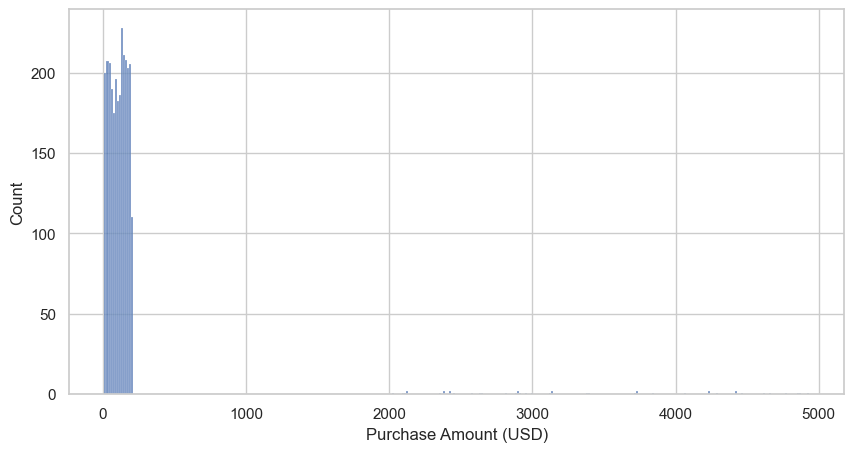

In [17]:
sns.histplot(data=df_toko, x="Purchase Amount (USD)")
plt.show()

In [18]:
df_toko.duplicated().sum()

np.int64(0)

In [19]:
kolom_kunci = ["Customer Reference ID", "Item Purchased", "Date Purchase"]
df_toko[df_toko.duplicated(subset=kolom_kunci, keep=False)].sort_values(kolom_kunci)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method,harga_kosong
2058,3983,Wallet,NaN,22-09-2023,5.0,Cash,True
2170,3983,Wallet,19.0,22-09-2023,2.4,Cash,False
819,4064,Sandals,154.0,08-10-2022,2.7,Cash,False
2720,4064,Sandals,131.0,08-10-2022,3.7,Cash,False
2479,4107,Swimsuit,110.0,02-07-2023,4.1,Cash,False
2686,4107,Swimsuit,112.0,02-07-2023,1.4,Credit Card,False


In [20]:
df_toko["Item Purchased"].nunique()

50

In [36]:
df_toko["Item Purchased"].unique()

array(['Handbag', 'Tunic', 'Tank Top', 'Leggings', 'Wallet', 'Onesie',
       'Jacket', 'Trousers', 'Jeans', 'Loafers', 'Slippers', 'Bowtie',
       'Pajamas', 'Trench Coat', 'Poncho', 'Gloves', 'Romper', 'T-shirt',
       'Flip-Flops', 'Shorts', 'Blazer', 'Boots', 'Belt', 'Hoodie',
       'Sweater', 'Blouse', 'Swimsuit', 'Kimono', 'Cardigan', 'Socks',
       'Pants', 'Scarf', 'Backpack', 'Dress', 'Camisole', 'Sneakers',
       'Flannel Shirt', 'Tie', 'Polo Shirt', 'Umbrella', 'Hat', 'Sun Hat',
       'Overalls', 'Coat', 'Sunglasses', 'Vest', 'Sandals', 'Jumpsuit',
       'Raincoat', 'Skirt'], dtype=object)

In [21]:
df_toko["Item Purchased"].str.strip().str.lower().nunique()

50

In [22]:
df_toko["Date Purchase"] = pd.to_datetime(df_toko["Date Purchase"], format="%d-%m-%Y", errors="coerce")

In [23]:
tanggal_uji = df_toko["Date Purchase"]

In [24]:
tanggal_uji.isna().sum()

np.int64(0)

In [25]:
tanggal_uji.min(), tanggal_uji.max()

(Timestamp('2022-10-02 00:00:00'), Timestamp('2023-10-01 00:00:00'))

In [26]:
tanggal_uji.dt.to_period("M").value_counts().sort_index()

Date Purchase
2022-10    309
2022-11    238
2022-12    306
2023-01    292
2023-02    251
2023-03    277
2023-04    295
2023-05    308
2023-06    262
2023-07    303
2023-08    301
2023-09    253
2023-10      5
Freq: M, Name: count, dtype: int64

In [27]:
df_toko[df_toko["Purchase Amount (USD)"] > 1000].index

Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
       36, 37, 38, 39, 40, 41, 42],
      dtype='int64')

In [28]:
df_toko.iloc[:43].head(15)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method,harga_kosong
0,4018,Handbag,4619.0,2023-02-05,NaN,Credit Card,False
1,4115,Tunic,2456.0,2023-07-11,2.0,Credit Card,False
2,4019,Tank Top,2102.0,2023-03-23,4.1,Cash,False
3,4097,Leggings,3126.0,2023-03-15,3.2,Cash,False
4,3997,Wallet,3003.0,2022-11-27,4.7,Cash,False
5,4080,Onesie,2914.0,2022-12-11,4.5,Credit Card,False
6,4055,Jacket,2571.0,2023-07-08,1.3,Cash,False
7,3973,Trousers,2419.0,2022-11-10,4.6,Cash,False
8,4044,Jeans,4771.0,2023-05-19,4.1,Cash,False
9,4010,Loafers,4233.0,2023-06-11,NaN,Credit Card,False


In [29]:
df_toko["Purchase Amount (USD)"].iloc[:43].agg(['min', 'max'])

min    2026.0
max    4932.0
Name: Purchase Amount (USD), dtype: float64

In [30]:
df_toko['Date Purchase'].iloc[:43].agg(['min', 'max'])

min   2022-10-11
max   2023-09-10
Name: Date Purchase, dtype: datetime64[ns]

In [31]:
df_toko.iloc[43:].head(15)

,Customer Reference ID,Item Purchased,Purchase Amount (USD),Date Purchase,Review Rating,Payment Method,harga_kosong
43,3992,Backpack,101.0,2022-12-13,1.3,Credit Card,False
44,4105,Dress,164.0,2022-10-20,3.2,Credit Card,False
45,4119,Boots,21.0,2023-04-03,3.9,Cash,False
46,3957,Camisole,147.0,2022-11-04,4.7,Cash,False
47,3994,Loafers,NaN,2023-05-16,3.9,Cash,True
48,3995,Bowtie,30.0,2022-11-23,4.1,Cash,False
49,4072,Poncho,170.0,2022-10-15,3.6,Credit Card,False
50,4093,Trousers,102.0,2023-05-25,2.1,Cash,False
51,4031,Blouse,190.0,2023-01-14,3.0,Cash,False
52,4056,Sneakers,NaN,2022-11-02,NaN,Credit Card,True


In [32]:
df_toko["Purchase Amount (USD)"].iloc[43:].agg(['min', 'max'])

min     10.0
max    200.0
Name: Purchase Amount (USD), dtype: float64

In [33]:
df_cek = df_toko.copy()
df_cek["tagihan_kosong"] = df_cek["Purchase Amount (USD)"].isna()

In [34]:
# per metode bayar: persentase kosong dan jumlah baris
df_cek.groupby("Payment Method")["tagihan_kosong"].agg(["mean", "count"])

,mean,count
Payment Method,,
Cash,0.195092,1630
Credit Card,0.187571,1770


In [35]:
df_cek["bulan"] = df_cek["Date Purchase"].dt.to_period("M")
df_cek.groupby("bulan")["tagihan_kosong"].agg(["mean", "count"])

,mean,count
bulan,,
2022-10,0.203883,309
2022-11,0.168067,238
2022-12,0.189542,306
2023-01,0.188356,292
2023-02,0.211155,251
2023-03,0.162455,277
2023-04,0.203390,295
2023-05,0.188312,308
2023-06,0.202290,262
